In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import numpy as np
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("GPU:")
print(tf.config.list_physical_devices("GPU"))

print("\nDatasets available in Kaggle:")
print(os.listdir("/kaggle/input"))

TensorFlow version: 2.20.0
GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Datasets available in Kaggle:
['datasets']


In [2]:
import os

DATASET_PATH = "/kaggle/input/datasets"

print("Dataset contents:")
print(os.listdir(DATASET_PATH))

Dataset contents:
['praneethkanike']


In [3]:
DATASET_PATH = "/kaggle/input/datasets/praneethkanike"

print("Inside praneethkanike:")
print(os.listdir(DATASET_PATH))

Inside praneethkanike:
['deepfake-image-detection']


In [4]:
import os

DATASET_PATH = "/kaggle/input/datasets/praneethkanike/deepfake-image-detection"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    indent = "    " * level
    print(indent + os.path.basename(root) + "/")

deepfake-image-detection/
    40db316d-9702-4665-9551-c010f9803a3a/
        AIGenerated_Images/
    2f068519-71be-485f-8979-0f9d4434adb8/
        Real_Images/


In [5]:
import os

AI_DIR = "/kaggle/input/datasets/praneethkanike/deepfake-image-detection/40db316d-9702-4655-9551-c010f9803a3a/AIGenerated_Images"

REAL_DIR = "/kaggle/input/datasets/praneethkanike/deepfake-image-detection/2f068519-71be-485f-8979-0f9d4434adb8/Real_Images"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

ai_images = [
    f for f in os.listdir(AI_DIR)
    if f.lower().endswith(image_extensions)
]

real_images = [
    f for f in os.listdir(REAL_DIR)
    if f.lower().endswith(image_extensions)
]

print("AI-generated images:", len(ai_images))
print("Real images:", len(real_images))
print("Total images:", len(ai_images) + len(real_images))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/datasets/praneethkanike/deepfake-image-detection/40db316d-9702-4655-9551-c010f9803a3a/AIGenerated_Images'

In [6]:
import os

DATASET_PATH = "/kaggle/input/datasets/praneethkanike/deepfake-image-detection"

AI_DIR = None
REAL_DIR = None

for root, dirs, files in os.walk(DATASET_PATH):
    folder_name = os.path.basename(root).lower()

    if "aigenerated" in folder_name:
        AI_DIR = root

    if "real_images" in folder_name:
        REAL_DIR = root

print("AI folder:", AI_DIR)
print("REAL folder:", REAL_DIR)

AI folder: /kaggle/input/datasets/praneethkanike/deepfake-image-detection/40db316d-9702-4665-9551-c010f9803a3a/AIGenerated_Images
REAL folder: /kaggle/input/datasets/praneethkanike/deepfake-image-detection/2f068519-71be-485f-8979-0f9d4434adb8/Real_Images


In [7]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

ai_images = [
    f for f in os.listdir(AI_DIR)
    if f.lower().endswith(image_extensions)
]

real_images = [
    f for f in os.listdir(REAL_DIR)
    if f.lower().endswith(image_extensions)
]

print("AI-generated images:", len(ai_images))
print("Real images:", len(real_images))
print("Total images:", len(ai_images) + len(real_images))

AI-generated images: 1242
Real images: 76
Total images: 1318


In [8]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

real_path = os.path.join(REAL_DIR, real_images[0])
ai_path = os.path.join(AI_DIR, ai_images[0])

real_img = np.array(Image.open(real_path).convert("RGB"))
ai_img = np.array(Image.open(ai_path).convert("RGB"))

print("REAL image")
print("Shape:", real_img.shape)
print("Mean:", np.mean(real_img))
print("Standard deviation:", np.std(real_img))
print("Minimum:", np.min(real_img))
print("Maximum:", np.max(real_img))

print("\nAI image")
print("Shape:", ai_img.shape)
print("Mean:", np.mean(ai_img))
print("Standard deviation:", np.std(ai_img))
print("Minimum:", np.min(ai_img))
print("Maximum:", np.max(ai_img))

REAL image
Shape: (3072, 3072, 3)
Mean: 175.25279426574707
Standard deviation: 52.31454105597525
Minimum: 23
Maximum: 255

AI image
Shape: (1920, 1280, 3)
Mean: 49.31929063585069
Standard deviation: 57.14440797668586
Minimum: 0
Maximum: 255


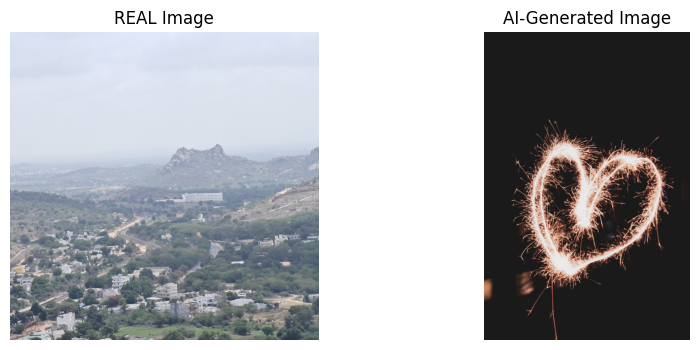

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(real_img)
plt.title("REAL Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(ai_img)
plt.title("AI-Generated Image")
plt.axis("off")

plt.show()

In [10]:
from sklearn.model_selection import train_test_split

all_files = []
all_labels = []

for filename in ai_images:
    all_files.append(os.path.join(AI_DIR, filename))
    all_labels.append(1)

for filename in real_images:
    all_files.append(os.path.join(REAL_DIR, filename))
    all_labels.append(0)

X_train, X_temp, y_train, y_temp = train_test_split(
    all_files,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 922
Validation images: 198
Testing images: 198


In [12]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )
    image = tf.cast(image, tf.float32)

    return image, label

In [13]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Datasets created successfully!")

Datasets created successfully!


I0000 00:00:1790952412.321934      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790952412.327738      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [14]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

print("Data augmentation ready!")

Data augmentation ready!


In [15]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [16]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = keras.Model(
    inputs,
    outputs
)

print("Model created successfully!")

Model created successfully!


In [17]:
model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [18]:
EPOCHS = 5

history = model.fit(
    train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE),
    validation_data=val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE),
    epochs=EPOCHS
)

Epoch 1/5
18/58 ━━━━━━━━━━━━━━━━━━━━ 8s 216ms/step - accuracy: 0.7495 - loss: 0.5380

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


36/58 ━━━━━━━━━━━━━━━━━━━━ 5s 227ms/step - accuracy: 0.7897 - loss: 0.4963

Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


58/58 ━━━━━━━━━━━━━━━━━━━━ 27s 315ms/step - accuracy: 0.8807 - loss: 0.3789 - val_accuracy: 0.9444 - val_loss: 0.2501
Epoch 2/5
18/58 ━━━━━━━━━━━━━━━━━━━━ 7s 178ms/step - accuracy: 0.9528 - loss: 0.2419

...

58/58 ━━━━━━━━━━━━━━━━━━━━ 12s 212ms/step - accuracy: 0.9425 - loss: 0.2495 - val_accuracy: 0.9444 - val_loss: 0.2304
Epoch 5/5
18/58 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step - accuracy: 0.9528 - loss: 0.2099

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


36/58 ━━━━━━━━━━━━━━━━━━━━ 3s 172ms/step - accuracy: 0.9478 - loss: 0.2232

Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


58/58 ━━━━━━━━━━━━━━━━━━━━ 12s 211ms/step - accuracy: 0.9425 - loss: 0.2328 - val_accuracy: 0.9444 - val_loss: 0.2273


In [19]:
test_loss, test_accuracy = model.evaluate(
    test_ds.batch(BATCH_SIZE),
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("-------------------------")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

 5/13 ━━━━━━━━━━━━━━━━━━━━ 2s 330ms/step - accuracy: 0.9306 - loss: 0.2622

Corrupt JPEG data: 1 extraneous bytes before marker 0xd7


 8/13 ━━━━━━━━━━━━━━━━━━━━ 2s 416ms/step - accuracy: 0.9355 - loss: 0.2466

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 387ms/step - accuracy: 0.9394 - loss: 0.2292

FINAL TEST RESULTS
-------------------------
Test Loss: 0.22918176651000977
Test Accuracy: 0.939393937587738
Test Accuracy (%): 93.9393937587738


In [20]:
import numpy as np
from sklearn.metrics import classification_report

y_prob = model.predict(
    test_ds.batch(BATCH_SIZE)
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["REAL", "AI"],
    zero_division=0
))

 5/13 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step

Corrupt JPEG data: 1 extraneous bytes before marker 0xd7


 8/13 ━━━━━━━━━━━━━━━━━━━━ 1s 243ms/step

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 323ms/step
              precision    recall  f1-score   support

        REAL       0.00      0.00      0.00        12
          AI       0.94      1.00      0.97       186

    accuracy                           0.94       198
   macro avg       0.47      0.50      0.48       198
weighted avg       0.88      0.94      0.91       198



[[  0  12]
 [  0 186]]


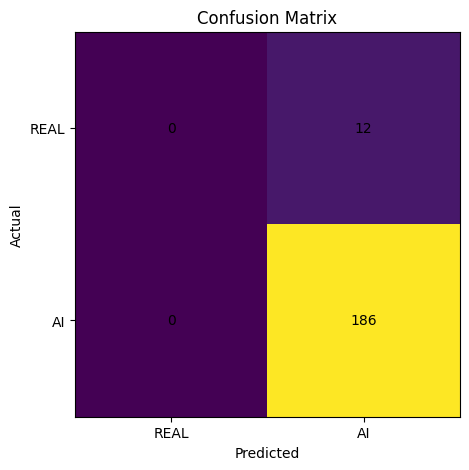

In [21]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)

plt.xticks([0, 1], ["REAL", "AI"])
plt.yticks([0, 1], ["REAL", "AI"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

ROC-AUC: 0.6017025089605735


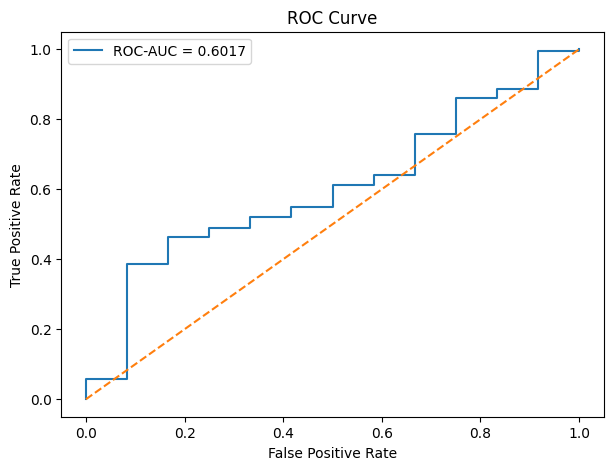

In [22]:
from sklearn.metrics import roc_curve, roc_auc_score

auc = roc_auc_score(y_test, y_prob)

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

print("ROC-AUC:", auc)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

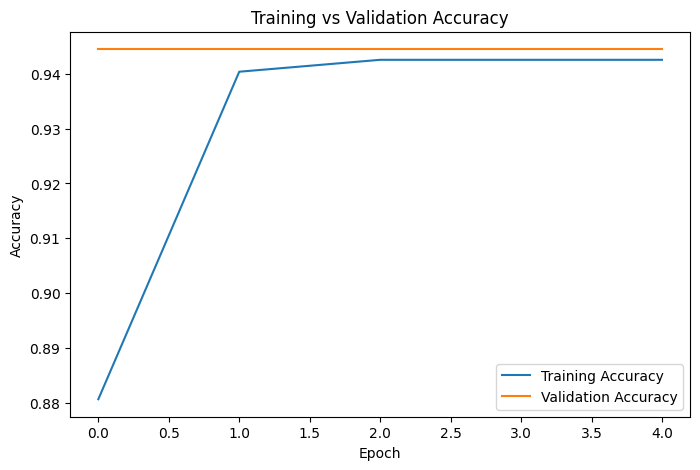

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

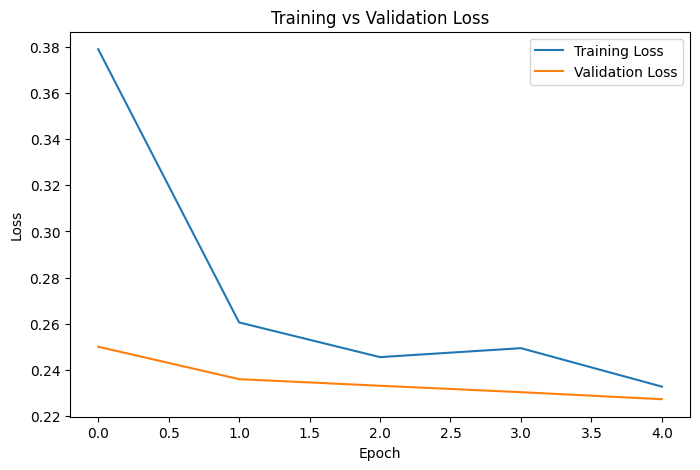

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

In [25]:
model.save(
    "/kaggle/working/deepfake_mobilenetv2.keras"
)

print("Model saved successfully!")

Model saved successfully!


In [26]:
import os

print(
    os.path.exists(
        "/kaggle/working/deepfake_mobilenetv2.keras"
    )
)

True


In [27]:
test_loss, test_accuracy = model.evaluate(
    test_ds.batch(BATCH_SIZE),
    verbose=1
)

print("FINAL TEST ACCURACY:", test_accuracy * 100, "%")

 5/13 ━━━━━━━━━━━━━━━━━━━━ 1s 174ms/step - accuracy: 0.9306 - loss: 0.2622

Corrupt JPEG data: 1 extraneous bytes before marker 0xd7


 8/13 ━━━━━━━━━━━━━━━━━━━━ 1s 295ms/step - accuracy: 0.9355 - loss: 0.2466

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 265ms/step - accuracy: 0.9394 - loss: 0.2292
FINAL TEST ACCURACY: 93.9393937587738 %


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def predict_image(image_path):
    
    img = tf.io.read_file(image_path)
    
    img = tf.image.decode_image(
        img,
        channels=3,
        expand_animations=False
    )
    
    img = tf.image.resize(
        img,
        [224, 224]
    )
    
    img = tf.cast(
        img,
        tf.float32
    )
    
    img = preprocess_input(img)
    
    img = tf.expand_dims(
        img,
        axis=0
    )
    
    probability = model.predict(
        img,
        verbose=0
    )[0][0]
    
    if probability >= 0.5:
        prediction = "AI"
        confidence = probability
    else:
        prediction = "REAL"
        confidence = 1 - probability
    
    return prediction, confidence

In [30]:
real_indices = [i for i, label in enumerate(y_test) if label == 0]

real_index = real_indices[0]

real_test_image = X_test[real_index]

print("REAL test image selected:")
print(real_test_image)

REAL test image selected:
/kaggle/input/datasets/praneethkanike/deepfake-image-detection/2f068519-71be-485f-8979-0f9d4434adb8/Real_Images/20250414_174940.jpg


In [31]:
prediction, confidence = predict_image(real_test_image)

print("Actual Label: REAL")
print("Predicted Label:", prediction)
print("Confidence:", f"{confidence * 100:.2f}%")

NameError: name 'preprocess_input' is not defined

In [50]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [51]:
prediction, confidence = predict_image(real_test_image)

print("Actual Label: REAL")
print("Predicted Label:", prediction)
print("Confidence:", f"{confidence * 100:.2f}%")

Actual Label: REAL
Predicted Label: AI
Confidence: 86.54%


In [52]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

img = tf.io.read_file(real_test_image)

img = tf.image.decode_image(
    img,
    channels=3,
    expand_animations=False
)

img = tf.image.resize(
    img,
    [224, 224]
)

img = tf.cast(
    img,
    tf.float32
)

img = preprocess_input(img)

img = tf.expand_dims(
    img,
    axis=0
)

probability = model.predict(
    img,
    verbose=0
)[0][0]

if probability >= 0.5:
    prediction = "AI"
    confidence = probability
else:
    prediction = "REAL"
    confidence = 1 - probability

print("Actual Label: REAL")
print("Predicted Label:", prediction)
print("Confidence:", f"{confidence * 100:.2f}%")

Actual Label: REAL
Predicted Label: AI
Confidence: 86.54%


In [53]:
test_loss, test_accuracy = model.evaluate(
    test_ds.batch(BATCH_SIZE),
    verbose=1
)

print("====================================")
print("FINAL TEST RESULTS")
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")
print("Test Loss:", f"{test_loss:.4f}")
print("====================================")

 5/13 ━━━━━━━━━━━━━━━━━━━━ 1s 178ms/step - accuracy: 0.9306 - loss: 0.2622

Corrupt JPEG data: 1 extraneous bytes before marker 0xd7


 8/13 ━━━━━━━━━━━━━━━━━━━━ 1s 293ms/step - accuracy: 0.9355 - loss: 0.2466

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 267ms/step - accuracy: 0.9394 - loss: 0.2292
FINAL TEST RESULTS
Test Accuracy: 93.94%
Test Loss: 0.2292


In [54]:
from sklearn.metrics import classification_report

y_prob = model.predict(
    test_ds.batch(BATCH_SIZE),
    verbose=0
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("CLASSIFICATION REPORT")
print("=====================")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["REAL", "AI"],
        digits=4
    )
)

Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        REAL     0.0000    0.0000    0.0000        12
          AI     0.9394    1.0000    0.9688       186

    accuracy                         0.9394       198
   macro avg     0.4697    0.5000    0.4844       198
weighted avg     0.8825    0.9394    0.9100       198



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [56]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = {
    int(classes[i]): float(class_weights[i])
    for i in range(len(classes))
}

print("Class weights:")
print(class_weight_dict)

print("\nTraining class distribution:")
print("REAL:", sum(np.array(y_train) == 0))
print("AI:", sum(np.array(y_train) == 1))

Class weights:
{0: 8.69811320754717, 1: 0.5304948216340621}

Training class distribution:
REAL: 53
AI: 869


In [57]:
history_balanced = model.fit(
    train_ds.batch(BATCH_SIZE),
    validation_data=val_ds.batch(BATCH_SIZE),
    epochs=5,
    class_weight=class_weight_dict
)

Epoch 1/5
18/58 ━━━━━━━━━━━━━━━━━━━━ 7s 188ms/step - accuracy: 0.9528 - loss: 1.1195

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


36/58 ━━━━━━━━━━━━━━━━━━━━ 4s 184ms/step - accuracy: 0.9450 - loss: 1.1769

Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


58/58 ━━━━━━━━━━━━━━━━━━━━ 16s 228ms/step - accuracy: 0.8742 - loss: 1.0348 - val_accuracy: 0.8434 - val_loss: 0.5317
Epoch 2/5
18/58 ━━━━━━━━━━━━━━━━━━━━ 6s 173ms/step - accuracy: 0.7190 - loss: 0.6269

...

58/58 ━━━━━━━━━━━━━━━━━━━━ 12s 205ms/step - accuracy: 0.5683 - loss: 0.6706 - val_accuracy: 0.5505 - val_loss: 0.6605
Epoch 5/5
17/58 ━━━━━━━━━━━━━━━━━━━━ 7s 182ms/step - accuracy: 0.6371 - loss: 0.5557

Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


36/58 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.6156 - loss: 0.6213

Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


58/58 ━━━━━━━━━━━━━━━━━━━━ 12s 205ms/step - accuracy: 0.6020 - loss: 0.6773 - val_accuracy: 0.5354 - val_loss: 0.6743


In [58]:
import random
import numpy as np
from sklearn.model_selection import train_test_split

random.seed(42)
np.random.seed(42)

real_paths = [
    os.path.join(REAL_DIR, f)
    for f in os.listdir(REAL_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

ai_paths = [
    os.path.join(AI_DIR, f)
    for f in os.listdir(AI_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

random.shuffle(real_paths)
random.shuffle(ai_paths)

n = min(len(real_paths), len(ai_paths))

real_paths = real_paths[:n]
ai_paths = ai_paths[:n]

balanced_paths = real_paths + ai_paths
balanced_labels = [0] * n + [1] * n

X_train, X_temp, y_train, y_temp = train_test_split(
    balanced_paths,
    balanced_labels,
    test_size=0.30,
    random_state=42,
    stratify=balanced_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Balanced dataset created")
print("------------------------")
print("REAL images:", n)
print("AI images:", n)
print("Total images:", len(balanced_paths))
print()
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print()
print("Training REAL:", sum(np.array(y_train) == 0))
print("Training AI:", sum(np.array(y_train) == 1))
print("Testing REAL:", sum(np.array(y_test) == 0))
print("Testing AI:", sum(np.array(y_test) == 1))

NameError: name 'IMAGE_EXTENSIONS' is not defined

In [59]:
import random
import numpy as np
from sklearn.model_selection import train_test_split

random.seed(42)
np.random.seed(42)

real_paths = [
    os.path.join(REAL_DIR, f)
    for f in os.listdir(REAL_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

ai_paths = [
    os.path.join(AI_DIR, f)
    for f in os.listdir(AI_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

random.shuffle(real_paths)
random.shuffle(ai_paths)

n = min(len(real_paths), len(ai_paths))

real_paths = real_paths[:n]
ai_paths = ai_paths[:n]

balanced_paths = real_paths + ai_paths
balanced_labels = [0] * n + [1] * n

X_train, X_temp, y_train, y_temp = train_test_split(
    balanced_paths,
    balanced_labels,
    test_size=0.30,
    random_state=42,
    stratify=balanced_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Balanced dataset created")
print("------------------------")
print("REAL images:", n)
print("AI images:", n)
print("Total images:", len(balanced_paths))
print()
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print()
print("Training REAL:", sum(np.array(y_train) == 0))
print("Training AI:", sum(np.array(y_train) == 1))
print("Testing REAL:", sum(np.array(y_test) == 0))
print("Testing AI:", sum(np.array(y_test) == 1))

NameError: name 'IMAGE_EXTENSIONS' is not defined

In [60]:
import os
import random
import numpy as np
from sklearn.model_selection import train_test_split

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

random.seed(42)
np.random.seed(42)

real_paths = [
    os.path.join(REAL_DIR, f)
    for f in os.listdir(REAL_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

ai_paths = [
    os.path.join(AI_DIR, f)
    for f in os.listdir(AI_DIR)
    if f.lower().endswith(IMAGE_EXTENSIONS)
]

random.shuffle(real_paths)
random.shuffle(ai_paths)

n = min(len(real_paths), len(ai_paths))

real_paths = real_paths[:n]
ai_paths = ai_paths[:n]

balanced_paths = real_paths + ai_paths
balanced_labels = [0] * n + [1] * n

X_train, X_temp, y_train, y_temp = train_test_split(
    balanced_paths,
    balanced_labels,
    test_size=0.30,
    random_state=42,
    stratify=balanced_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Balanced dataset created")
print("------------------------")
print("REAL images:", n)
print("AI images:", n)
print("Total images:", len(balanced_paths))
print()
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print()
print("Training REAL:", sum(np.array(y_train) == 0))
print("Training AI:", sum(np.array(y_train) == 1))
print("Testing REAL:", sum(np.array(y_test) == 0))
print("Testing AI:", sum(np.array(y_test) == 1))

Balanced dataset created
------------------------
REAL images: 76
AI images: 76
Total images: 152

Training: 106
Validation: 23
Testing: 23

Training REAL: 53
Training AI: 53
Testing REAL: 12
Testing AI: 11


In [61]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
BATCH_SIZE = 16

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)

    return image, label


train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.shuffle(len(X_train), seed=42).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Balanced TensorFlow datasets created successfully")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Balanced TensorFlow datasets created successfully
Training batches: 7
Validation batches: 2
Testing batches: 2


In [62]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

tf.keras.backend.clear_session()

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Fresh MobileNetV2 model created")
print()
model.summary()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Fresh MobileNetV2 model created



Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

...

7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - accuracy: 0.4245 - loss: 0.8066 - val_accuracy: 0.4348 - val_loss: 0.7705
Epoch 4/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 111ms/step - accuracy: 0.5377 - loss: 0.7472 - val_accuracy: 0.4348 - val_loss: 0.7624
Epoch 5/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 110ms/step - accuracy: 0.5849 - loss: 0.7592 - val_accuracy: 0.4348 - val_loss: 0.7540


In [63]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning enabled")
print("Trainable parameters:", sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
))

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Fine-tuning enabled
Trainable parameters: 1527681
Epoch 1/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 355ms/step - accuracy: 0.6226 - loss: 0.6284 - val_accuracy: 0.5217 - val_loss: 0.7255
Epoch 2/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - accuracy: 0.6132 - loss: 0.6417 - val_accuracy: 0.5652 - val_loss: 0.7003
Epoch 3/5


...

7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 117ms/step - accuracy: 0.6887 - loss: 0.5925 - val_accuracy: 0.5217 - val_loss: 0.6775
Epoch 4/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 116ms/step - accuracy: 0.6792 - loss: 0.5772 - val_accuracy: 0.5652 - val_loss: 0.6584
Epoch 5/5


Corrupt JPEG data: 1 extraneous bytes before marker 0xd4
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1
Corrupt JPEG data: 1 extraneous bytes before marker 0xd7
Corrupt JPEG data: 1 extraneous bytes before marker 0xd1


7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - accuracy: 0.7170 - loss: 0.5219 - val_accuracy: 0.5652 - val_loss: 0.6440


In [64]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_true = []
y_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_prob.extend(predictions.ravel())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print("Test Accuracy:", f"{accuracy_score(y_true, y_pred) * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["REAL", "AI"],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Test Accuracy: 69.57%

Classification Report:
              precision    recall  f1-score   support

        REAL     0.6471    0.9167    0.7586        12
          AI     0.8333    0.4545    0.5882        11

    accuracy                         0.6957        23
   macro avg     0.7402    0.6856    0.6734        23
weighted avg     0.7361    0.6957    0.6771        23


Confusion Matrix:
[[11  1]
 [ 6  5]]


<Figure size 600x500 with 0 Axes>

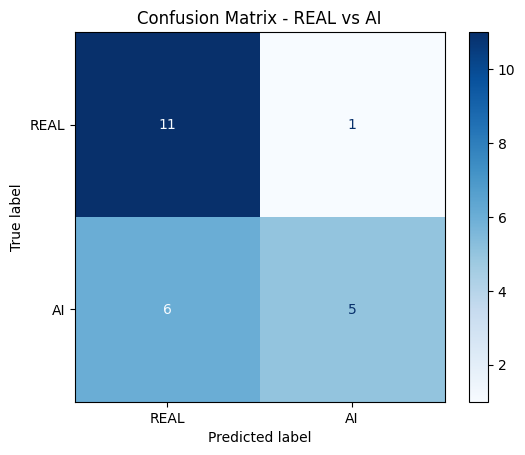

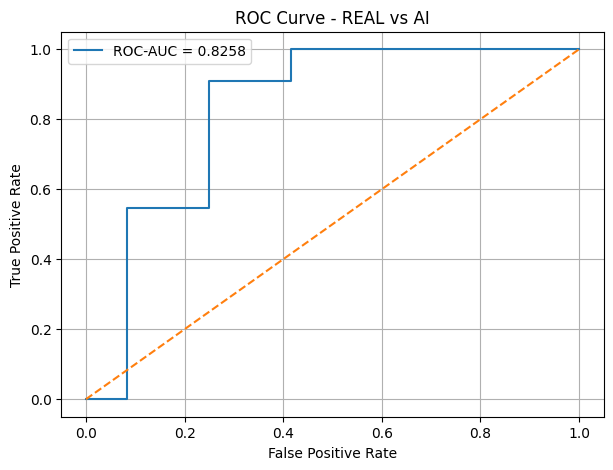

ROC-AUC Score: 0.8258


In [65]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["REAL", "AI"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - REAL vs AI")
plt.show()


fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc_score = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - REAL vs AI")
plt.legend()
plt.grid()
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f}")

REAL IMAGE PREDICTION


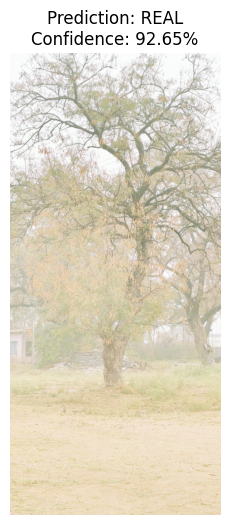

Image: /kaggle/input/datasets/praneethkanike/deepfake-image-detection/2f068519-71be-485f-8979-0f9d4434adb8/Real_Images/IMG20260101094902.jpg
Prediction: REAL
AI Probability: 0.0735
Confidence: 92.65%

AI IMAGE PREDICTION


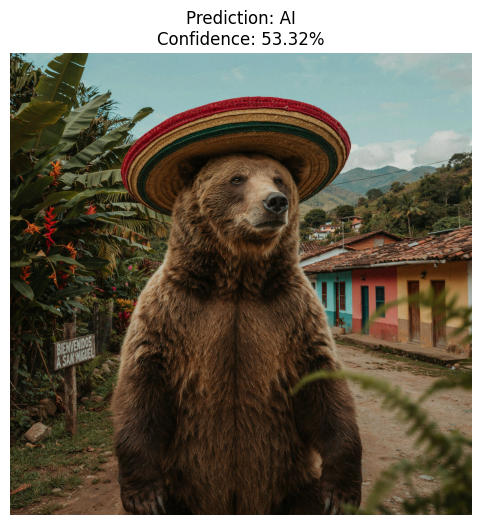

Image: /kaggle/input/datasets/praneethkanike/deepfake-image-detection/40db316d-9702-4665-9551-c010f9803a3a/AIGenerated_Images/high-level-description-a-casual-iphone-s_8eGZ1fNFV1i4TLhVUXHggA_HKhPbqIVQMubi5h5JROZLA.jpg
Prediction: AI
AI Probability: 0.5332
Confidence: 53.32%


In [66]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def predict_image(image_path):
    image = Image.open(image_path).convert("RGB")
    display_image = image.copy()

    image = image.resize((224, 224))
    image_array = np.array(image, dtype=np.float32)
    image_array = preprocess_input(image_array)
    image_array = np.expand_dims(image_array, axis=0)

    probability = float(model.predict(image_array, verbose=0)[0][0])

    if probability >= 0.5:
        prediction = "AI"
        confidence = probability * 100
    else:
        prediction = "REAL"
        confidence = (1 - probability) * 100

    plt.figure(figsize=(6, 6))
    plt.imshow(display_image)
    plt.axis("off")
    plt.title(f"Prediction: {prediction}\nConfidence: {confidence:.2f}%")
    plt.show()

    print("Image:", image_path)
    print("Prediction:", prediction)
    print(f"AI Probability: {probability:.4f}")
    print(f"Confidence: {confidence:.2f}%")

print("REAL IMAGE PREDICTION")
real_test_image = random.choice([p for p, y in zip(X_test, y_test) if y == 0])
predict_image(real_test_image)

print("\nAI IMAGE PREDICTION")
ai_test_image = random.choice([p for p, y in zip(X_test, y_test) if y == 1])
predict_image(ai_test_image)

In [67]:
final_model_path = "/kaggle/working/deepfake_mobilenetv2_final.keras"

model.save(final_model_path)

print("Final model saved successfully!")
print("Model path:", final_model_path)

import os

if os.path.exists(final_model_path):
    file_size_mb = os.path.getsize(final_model_path) / (1024 * 1024)
    print(f"Model size: {file_size_mb:.2f} MB")
    print("File exists: True")
else:
    print("File exists: False")

Final model saved successfully!
Model path: /kaggle/working/deepfake_mobilenetv2_final.keras
Model size: 20.87 MB
File exists: True


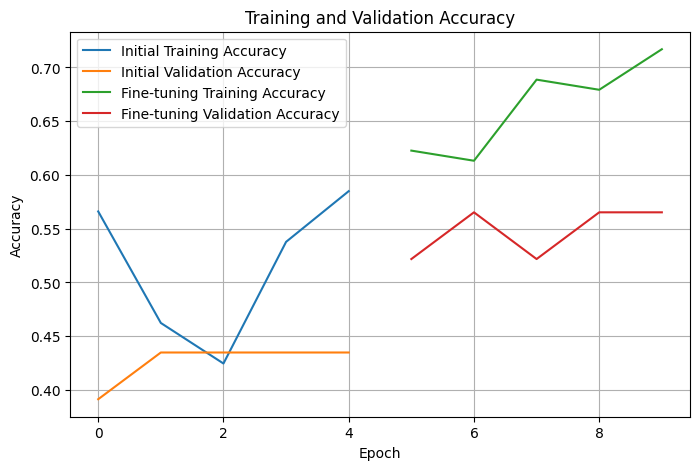

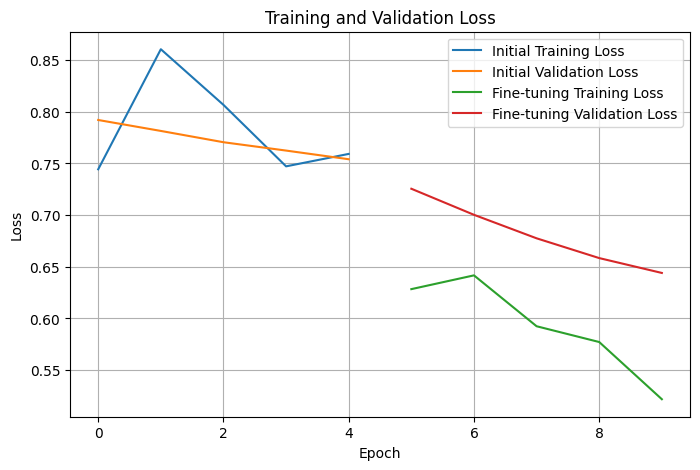

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Initial Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Initial Validation Accuracy"
)

plt.plot(
    range(
        len(history.history["accuracy"]),
        len(history.history["accuracy"]) + len(history_finetune.history["accuracy"])
    ),
    history_finetune.history["accuracy"],
    label="Fine-tuning Training Accuracy"
)

plt.plot(
    range(
        len(history.history["val_accuracy"]),
        len(history.history["val_accuracy"]) + len(history_finetune.history["val_accuracy"])
    ),
    history_finetune.history["val_accuracy"],
    label="Fine-tuning Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Initial Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Initial Validation Loss"
)

plt.plot(
    range(
        len(history.history["loss"]),
        len(history.history["loss"]) + len(history_finetune.history["loss"])
    ),
    history_finetune.history["loss"],
    label="Fine-tuning Training Loss"
)

plt.plot(
    range(
        len(history.history["val_loss"]),
        len(history.history["val_loss"]) + len(history_finetune.history["val_loss"])
    ),
    history_finetune.history["val_loss"],
    label="Fine-tuning Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()